# AI Museum Guide — Image Style Classification

This notebook is a simple, shared workspace for the project. It follows the main workflow: **load the dataset → prepare images → train an FNN → train a pretrained ResNet → compare results**.

Read the comments (`# ...`) in each code cell before running it. The FNN section is implemented as a baseline. The ResNet and final comparison sections are left for the teammate responsible for them to complete, following the project instructions.

**Dataset folder:** `data/wikiart_subset/`

Expected structure:
- `Baroque/`
- `Cubism/`
- `Impressionism/`
- `Pop_Art/`
- `Ukiyo_e/`

Each class folder should contain its images.


## 1. Import libraries and set project paths

This section imports the tools used in the notebook and defines a few settings in one place. If the dataset folder is named differently, update `DATA_DIR`.


In [1]:
# Path helps Python find files and folders.
from pathlib import Path
import json
import random

In [2]:
# Path helps Python find files and folders.
from pathlib import Path
import json
import random

In [4]:
%pip install torch torchvision matplotlib pillow

  Using cached torch-2.14.1-cp314-cp314-macosx_14_0_arm64.whl.metadata (39 kB)
  Using cached torchvision-0.29.1-cp314-cp314-macosx_14_0_arm64.whl.metadata (5.7 kB)
  Using cached pillow-13.0.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (9.1 kB)
  Using cached filelock-4.2.0-py3-none-any.whl.metadata (2.0 kB)
  Using cached typing_extensions-4.16.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached setuptools-84.0.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached numpy-2.5.4-cp314-cp314-macosx_14_0_arm64.whl.metadata (6.6 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
  Using cached markupsafe-3.0.4-cp314-cp314-macosx_11_0_arm64.whl.metadata (2.7 kB)
Using cached torch-2.14.1-cp314-cp314-macosx_14_0_arm64.whl (127.3 M

In [6]:
# PyTorch is used to build and train neural networks.
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

# Matplotlib draws training graphs.
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [7]:
# Set a fixed random seed so the data split and initial setup can be reproduced.
SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

# Change this path only if your dataset is stored somewhere else.
DATA_DIR = Path("data/wikiart_subset")

# All model results will be saved here.
OUTPUT_DIR = Path("outputs")
IMAGE_SIZE = 64       # FNN images are resized to 64 by 64 pixels.
BATCH_SIZE = 32       # Number of images processed together.
EPOCHS = 10            # Number of full passes through the training data.
LEARNING_RATE = 0.001  # Controls how large each optimizer update is.

# Use a GPU if PyTorch can access one; otherwise use the CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Dataset path:", DATA_DIR.resolve())

Device: cpu
Dataset path: /Users/tranngocminhhoang/Documents/Netral Network Project/Project-HSM/data/wikiart_subset


## 2. Check the dataset

Before training, verify that Python can find the dataset and that each class folder contains images. `ImageFolder` uses the names of the subfolders as class labels.


In [8]:
# Stop with a clear message if the path is wrong.
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATA_DIR.resolve()}\n"
        "Run this notebook from the project root, or update DATA_DIR."
    )

# Count common image formats in each class folder.
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
for folder in sorted(p for p in DATA_DIR.iterdir() if p.is_dir()):
    image_count = sum(
        1 for file in folder.rglob("*")
        if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS
    )
    print(f"{folder.name}: {image_count} images")

# ImageFolder reads images from subfolders and assigns each folder a numeric label.

Baroque: 100 images
Cubism: 100 images
Impressionism: 100 images
Pop_Art: 100 images
Ukiyo_e: 100 images


## 3. Prepare images and split the dataset

Neural networks need images converted into tensors. For the FNN baseline, each image is resized to `64 × 64` and converted into numbers between 0 and 1.

We split the data into:
- **Training set (70%)** — updates the model's weights.
- **Validation set (15%)** — helps monitor training and select a model.
- **Test set (15%)** — used for the final evaluation after model selection.

The split below is reproducible, but it is a simple random split. If the assignment requires class-balanced splitting, replace it with a stratified split.


In [9]:
# Resize each image to a fixed size, then convert it to a PyTorch tensor.
fnn_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])

# Load the images and labels from the class folders.
dataset = datasets.ImageFolder(DATA_DIR, transform=fnn_transform)
classes = dataset.classes

# Basic checks help catch a wrong or empty dataset early.
if len(classes) < 2:
    raise ValueError("At least two class folders containing images are required.")
if len(dataset) < 10:
    raise ValueError("Too few images found. Please check the dataset.")

# Calculate the number of images in each split.
total_images = len(dataset)
train_size = int(total_images * 0.70)
val_size = int(total_images * 0.15)
test_size = total_images - train_size - val_size

# Use a fixed seed so the split stays the same when rerun.
split_generator = torch.Generator().manual_seed(SEED)
train_set, val_set, test_set = random_split(
    dataset, [train_size, val_size, test_size], generator=split_generator
)

# DataLoader serves batches of images to the model.
# Shuffle only the training set so the model does not see the same order every epoch.
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print("Class labels:", classes)
print(f"Total: {total_images} | Train: {len(train_set)} | Validation: {len(val_set)} | Test: {len(test_set)}")


Class labels: ['Baroque', 'Cubism', 'Impressionism', 'Pop_Art', 'Ukiyo_e']
Total: 500 | Train: 350 | Validation: 75 | Test: 75


## 4. Build the FNN model

A feed-forward neural network (FNN) receives a flattened image vector. The hidden layers learn patterns from the pixel values, and the final layer returns one score for each art style.

This is a simple baseline. Unlike a CNN, an FNN does not directly preserve the spatial layout of the image.


In [10]:
class FNN(nn.Module):
    def __init__(self, input_size, number_of_classes):
        super().__init__()

        # Each image has 3 colour channels, height 64, and width 64.
        # Flattening gives 3 * 64 * 64 input values per image.
        self.layers = nn.Sequential(
            nn.Linear(input_size, 512),  # First fully connected layer
            nn.ReLU(),                   # Adds non-linearity
            nn.Dropout(0.30),             # Reduces overfitting during training
            nn.Linear(512, 128),          # Second hidden layer
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(128, number_of_classes)  # One output score per class
        )

    def forward(self, images):
        # Keep the batch dimension; flatten channels, height, and width.
        images = torch.flatten(images, start_dim=1)
        # Return class scores (logits); CrossEntropyLoss handles these scores.
        return self.layers(images)


# Create the model and move it to the selected device.
input_size = 3 * IMAGE_SIZE * IMAGE_SIZE
fnn_model = FNN(input_size, len(classes)).to(device)

# CrossEntropyLoss is standard for multi-class classification.
loss_function = nn.CrossEntropyLoss()

# Adam updates the model weights to reduce the loss.
optimizer = torch.optim.Adam(fnn_model.parameters(), lr=LEARNING_RATE)

print(f"FNN input size: {input_size}")
print(f"Number of classes: {len(classes)}")


FNN input size: 12288
Number of classes: 5


## 5. Train the FNN

Each epoch consists of two passes:
1. **Training:** calculate predictions and loss, backpropagate the loss, and update weights.
2. **Validation:** measure performance without updating weights.

We save the checkpoint with the best validation accuracy so that the final test evaluation uses the selected model rather than simply the last epoch.


In [11]:
def run_epoch(model, data_loader, loss_function, optimizer=None):
    # An optimizer means this is a training pass. Without one, we only evaluate.
    is_training = optimizer is not None
    model.train(is_training)

    total_loss = 0.0
    total_correct = 0
    total_seen = 0

    # Disable gradient tracking for validation to save memory and computation.
    with torch.set_grad_enabled(is_training):
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            if is_training:
                optimizer.zero_grad()  # Clear gradients from the previous batch.

            predictions = model(images)
            loss = loss_function(predictions, labels)

            if is_training:
                loss.backward()  # Calculate gradients.
                optimizer.step()  # Update the model weights.

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (predictions.argmax(dim=1) == labels).sum().item()
            total_seen += batch_size

    if total_seen == 0:
        raise RuntimeError("The data loader is empty.")

    # Return average loss and accuracy across all images.
    return total_loss / total_seen, total_correct / total_seen


# Keep the metrics so we can plot and inspect learning behaviour later.
fnn_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
}

fnn_output_dir = OUTPUT_DIR / "fnn"
fnn_output_dir.mkdir(parents=True, exist_ok=True)
best_model_path = fnn_output_dir / "best_model.pt"
best_validation_accuracy = -1.0

for epoch in range(1, EPOCHS + 1):
    # Training updates the weights; validation only measures the model.
    train_loss, train_accuracy = run_epoch(
        fnn_model, train_loader, loss_function, optimizer
    )
    val_loss, val_accuracy = run_epoch(
        fnn_model, val_loader, loss_function
    )

    fnn_history["train_loss"].append(train_loss)
    fnn_history["train_accuracy"].append(train_accuracy)
    fnn_history["val_loss"].append(val_loss)
    fnn_history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | Train accuracy: {train_accuracy:.2%} | "
        f"Val loss: {val_loss:.4f} | Val accuracy: {val_accuracy:.2%}"
    )

    # Save a copy whenever validation accuracy improves.
    if val_accuracy > best_validation_accuracy:
        best_validation_accuracy = val_accuracy
        torch.save({
            "model_state_dict": fnn_model.state_dict(),
            "classes": classes,
            "image_size": IMAGE_SIZE,
        }, best_model_path)

# Save training history so it can be reused in the report.
(fnn_output_dir / "history.json").write_text(
    json.dumps(fnn_history, indent=2), encoding="utf-8"
)
print("Best FNN model saved to:", best_model_path)


Epoch 01/10 | Train loss: 2.9016 | Train accuracy: 18.86% | Val loss: 1.6916 | Val accuracy: 24.00%
Epoch 02/10 | Train loss: 1.7575 | Train accuracy: 21.71% | Val loss: 1.6011 | Val accuracy: 24.00%
Epoch 03/10 | Train loss: 1.6629 | Train accuracy: 22.29% | Val loss: 1.6290 | Val accuracy: 29.33%
Epoch 04/10 | Train loss: 1.6309 | Train accuracy: 23.43% | Val loss: 1.6252 | Val accuracy: 24.00%
Epoch 05/10 | Train loss: 1.6342 | Train accuracy: 20.00% | Val loss: 1.6123 | Val accuracy: 24.00%
Epoch 06/10 | Train loss: 1.6213 | Train accuracy: 25.14% | Val loss: 1.5869 | Val accuracy: 22.67%
Epoch 07/10 | Train loss: 1.6201 | Train accuracy: 21.14% | Val loss: 1.5972 | Val accuracy: 24.00%
Epoch 08/10 | Train loss: 1.6238 | Train accuracy: 20.57% | Val loss: 1.5903 | Val accuracy: 29.33%
Epoch 09/10 | Train loss: 1.6047 | Train accuracy: 26.00% | Val loss: 1.5843 | Val accuracy: 22.67%
Epoch 10/10 | Train loss: 1.6144 | Train accuracy: 22.86% | Val loss: 1.5860 | Val accuracy: 25.33%


## 6. Plot training results

Loss shows how wrong the model's predictions are according to the loss function; lower is generally better. Accuracy shows the fraction of images classified correctly.

Compare training and validation curves:
- Training improves but validation gets worse: possible overfitting.
- Both remain poor: possible underfitting, data issues, or a model that is too simple.
- Curves fluctuate strongly: the dataset may be small, or training settings may need review.


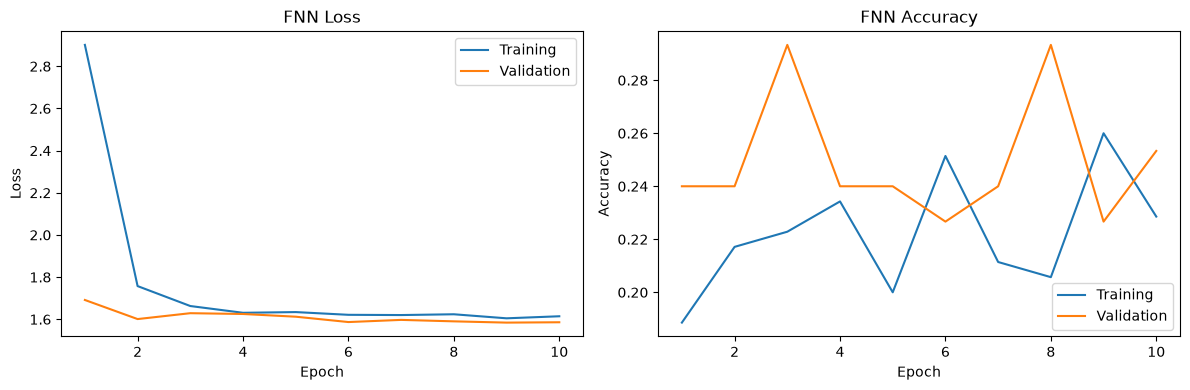

In [12]:
epochs_range = range(1, len(fnn_history["train_loss"]) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, fnn_history["train_loss"], label="Training")
plt.plot(epochs_range, fnn_history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("FNN Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, fnn_history["train_accuracy"], label="Training")
plt.plot(epochs_range, fnn_history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("FNN Accuracy")
plt.legend()

plt.tight_layout()
plt.show()


## 7. Evaluate the FNN on the test set

The test set is held back until model selection is complete. This gives a more honest estimate of performance on unseen images.

The code reloads the best validation checkpoint, then measures test loss and test accuracy.


In [13]:
# Load the checkpoint selected using validation accuracy.
checkpoint = torch.load(best_model_path, map_location=device)
fnn_model.load_state_dict(checkpoint["model_state_dict"])

# Evaluate without an optimizer, so weights are not updated.
test_loss, test_accuracy = run_epoch(
    fnn_model, test_loader, loss_function
)

print(f"FNN test loss: {test_loss:.4f}")
print(f"FNN test accuracy: {test_accuracy:.2%}")


FNN test loss: 1.6377
FNN test accuracy: 24.00%


## 8. Save the FNN results

The checkpoint stores the trained weights and class names. The JSON file stores the settings and final metrics so the team can report and compare experiments.


In [14]:
fnn_results = {
    "model": "FNN",
    "classes": classes,
    "total_images": len(dataset),
    "train_images": len(train_set),
    "validation_images": len(val_set),
    "test_images": len(test_set),
    "best_validation_accuracy": best_validation_accuracy,
    "test_loss": test_loss,
    "test_accuracy": test_accuracy,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "image_size": IMAGE_SIZE,
    "device": str(device),
}

(fnn_output_dir / "metrics.json").write_text(
    json.dumps(fnn_results, indent=2), encoding="utf-8"
)
print(json.dumps(fnn_results, indent=2))


{
  "model": "FNN",
  "classes": [
    "Baroque",
    "Cubism",
    "Impressionism",
    "Pop_Art",
    "Ukiyo_e"
  ],
  "total_images": 500,
  "train_images": 350,
  "validation_images": 75,
  "test_images": 75,
  "best_validation_accuracy": 0.29333333333333333,
  "test_loss": 1.6377292903264364,
  "test_accuracy": 0.24,
  "epochs": 10,
  "batch_size": 32,
  "learning_rate": 0.001,
  "image_size": 64,
  "device": "cpu"
}


## 9. ResNet model — teammate section

**Goal:** Train a pretrained ResNet model and compare it with the FNN baseline.

Complete this section using the project owner's requirements. Do not simply copy the FNN preprocessing: pretrained ResNet weights usually expect their own image size and normalization.

Steps for the teammate:
1. Select the ResNet version and pretrained weights.
2. Use the corresponding preprocessing transforms.
3. Create the ResNet and replace its final layer with the number of dataset classes.
4. Decide whether to freeze the backbone or fine-tune it.
5. Train using the training set and track validation metrics.
6. Save the best checkpoint and training history in `outputs/resnet/`.


In [ ]:
# TODO: ResNet implementation goes here.
# Reuse the dataset labels, but create ResNet-specific transforms and DataLoaders.
# Use validation results to select the best checkpoint.
# Save the checkpoint, training history, and metrics under OUTPUT_DIR / "resnet".


## 10. Compare FNN and ResNet

After the ResNet teammate completes Section 9, evaluate both selected checkpoints on the same held-out test examples.

Fill in this table with measured results; do not invent or estimate numbers.


| Model | Validation accuracy | Test accuracy | Test loss | Notes |
|---|---:|---:|---:|---|
| FNN | See `outputs/fnn/metrics.json` | See `outputs/fnn/metrics.json` | See `outputs/fnn/metrics.json` | Baseline |
| ResNet | TODO | TODO | TODO | TODO |

**Interpretation — fill in after experiments:**
- Which model performed better on the test set, and by how much?
- Did the training curves suggest overfitting?
- Which classes were most often confused, if a confusion matrix is required?
- What are the limitations of the dataset and experiment?


In [ ]:
# TODO: Add a fair comparison plot or metrics table after ResNet results are available.
# Optional, if required by the assignment: confusion matrix and per-class precision/recall/F1.


## 11. Predict the style of a new image — optional demo

This section can become a simple demo for the AI Museum Guide. The selected model must use the same preprocessing and class mapping as during training.

Before implementing, agree with the team whether the demo should use FNN, ResNet, or both.


In [ ]:
# TODO: Implement predict_image(image_path).
# Suggested behaviour:
# 1. Open the image.
# 2. Apply the selected model's preprocessing.
# 3. Load the saved checkpoint and class names.
# 4. Run inference without gradients.
# 5. Return the predicted style and, optionally, class scores.


## 12. Final project notes

### What remains
- Implement and evaluate ResNet.
- Compare FNN and ResNet on the same test set.
- Add any required confusion matrix or extra metrics.
- Complete the prediction demo if it is in scope.
- Update the README and presentation with measured results.
- Confirm the notebook runs from top to bottom in a fresh kernel.

### Important distinction
The current FNN classifies an image by **art style**. Searching for a painting from a natural-language question such as “Which painting shows a stormy sea?” is a separate image-text retrieval or metadata-search task. Only add that feature if it is required by the project outline.

### Final results summary
TODO: Write a short summary after the experiments are complete.
